## Function Minimization

In [73]:
import numpy as np
import matplotlib.pyplot as plt

Let us define the function we aim at maximizing. It is called a double-well function. It has two global minima.

In [74]:
def f(x):
    return x**4-8*(x**2)+5   #A double-well function with two global minima

In [ ]:
print(f(5))

430


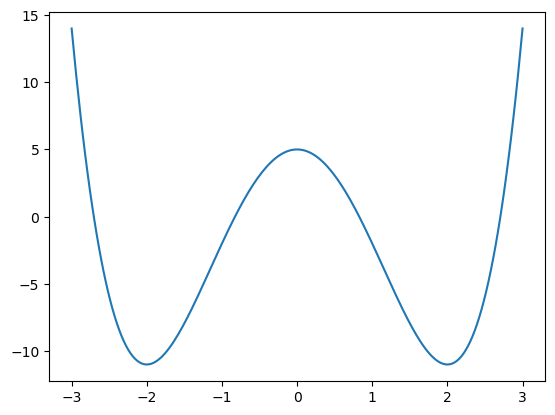

In [76]:
plt.plot(np.linspace(-3, 3, 200),f(np.linspace(-3,3,200)))

### Gradient descent

In [62]:
def grad_descent(x0, learning_rate=0.01, max_iter=10, tol=1e-6):
    x = x0
    iterations = np.array([x])
    for i in range(max_iter):
        grad = 4*x**3 - 16*x  # Derivative of f(x)
        x_new = x - learning_rate * grad
        iterations = np.append(iterations, x_new)
        if abs(x_new - x) < tol:
            break
        x = x_new
    return iterations

Let us test the algorithm.

In [63]:
algo=grad_descent(3, learning_rate=0.01, max_iter=20)

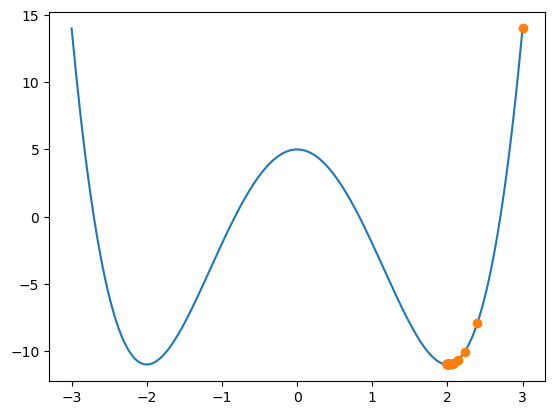

In [64]:
plt.plot(np.linspace(-3, 3, 200),f(np.linspace(-3,3,200)))
plt.plot(algo,f(algo),'o')
plt.show()

If we now we change the starting point of the algorithm, we shall obtain different results

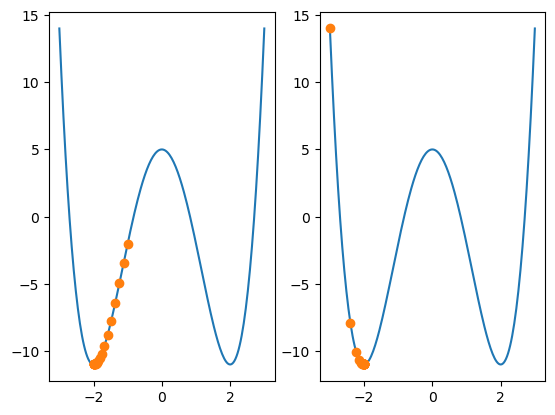

In [77]:
algo2= grad_descent(-1, learning_rate=0.01, max_iter=20)
algo3= grad_descent(-3, learning_rate=0.01, max_iter=20)
fig, axes = plt.subplots(1, 2,)
           # 2 rows, 3 columns j
axes[0].plot(np.linspace(-3, 3, 200),f(np.linspace(-3,3,200)))
axes[0].plot(algo2,f(algo2),'o')

axes[1].plot(np.linspace(-3, 3, 200),f(np.linspace(-3,3,200)))
axes[1].plot(algo3,f(algo3),'o')

plt.show()


## Newton's method

Here is an implementation of Newton's algorithm

In [66]:
def Newton(x0, max_iter, tol=1e-2):
        x = x0
        iterations = np.array([x])
        for i in range(max_iter):
            grad = 4*x**3 - 16*x  # Derivative of f(x)
            hess = 12*x**2 - 16 
            x_new = x -  grad/hess
            iterations = np.append(iterations, x_new)
            if abs(x_new - x) < tol:
                break
            x = x_new
        return iterations

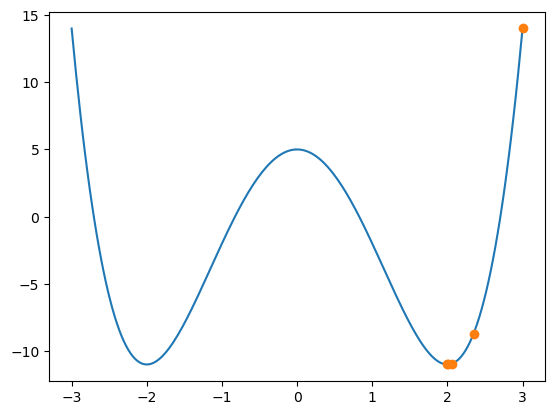

In [67]:
Newtalgo=Newton(3, max_iter=5)
plt.plot(np.linspace(-3, 3, 200),f(np.linspace(-3,3,200)))
plt.plot(Newtalgo,f(Newtalgo),'o')
plt.show()

In [68]:
Newtalgo 

array([3.        , 2.34782609, 2.06461425, 2.00291191, 2.00000634])

We can plot the values of $f$ along the algorithm

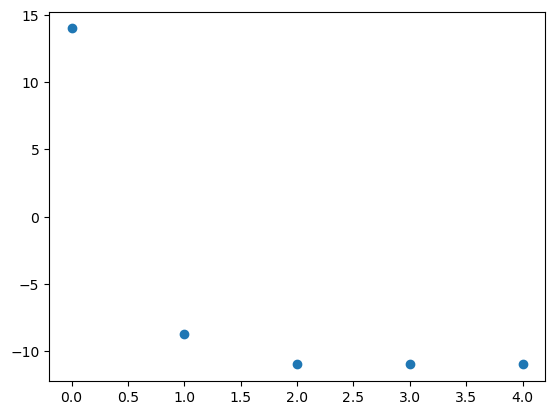

In [69]:
plt.plot(np.linspace(0,len(Newtalgo)-1,len(Newtalgo)),f(Newtalgo),'o')